In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping


diabetes = load_diabetes()


df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df['Progression'] = diabetes.target


df.head()


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Progression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [2]:

print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()


print("\nMissing Values:")
print(df.isnull().sum())


print("\nDuplicate Records:", df.duplicated().sum())


Dataset Shape: (442, 11)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          442 non-null    float64
 1   sex          442 non-null    float64
 2   bmi          442 non-null    float64
 3   bp           442 non-null    float64
 4   s1           442 non-null    float64
 5   s2           442 non-null    float64
 6   s3           442 non-null    float64
 7   s4           442 non-null    float64
 8   s5           442 non-null    float64
 9   s6           442 non-null    float64
 10  Progression  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB

Missing Values:
age            0
sex            0
bmi            0
bp             0
s1             0
s2             0
s3             0
s4             0
s5             0
s6             0
Progression    0
dtype: int64

Duplicate Records: 0


In [3]:
df.describe()


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Progression
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


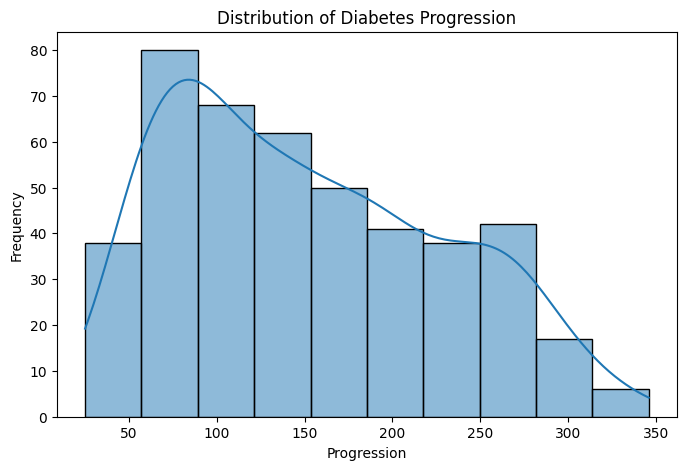

In [4]:
plt.figure(figsize=(8, 5))
sns.histplot(df['Progression'], kde=True)
plt.title('Distribution of Diabetes Progression')
plt.xlabel('Progression')
plt.ylabel('Frequency')
plt.show()


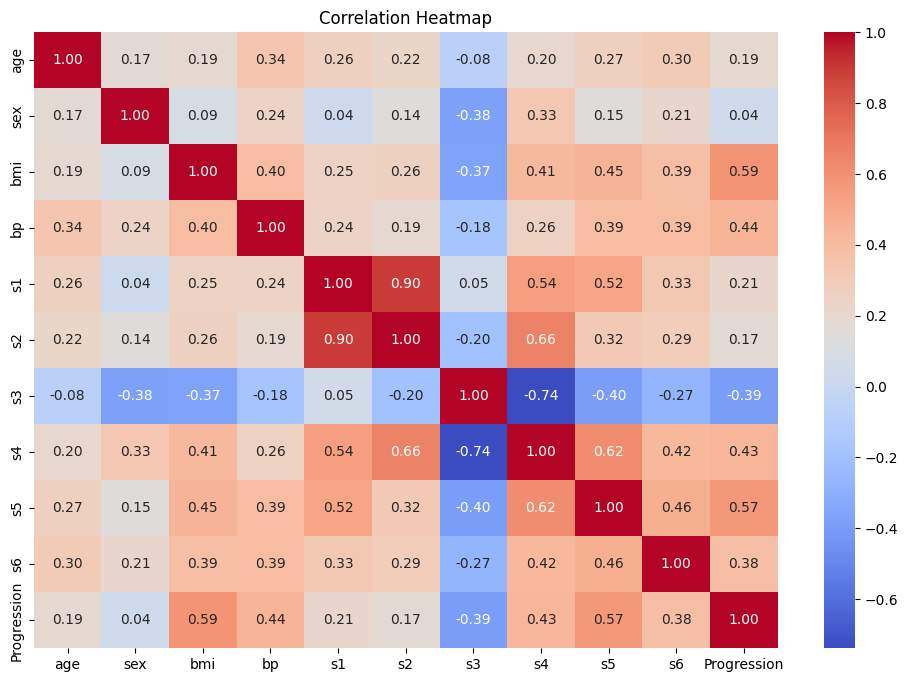

In [5]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()


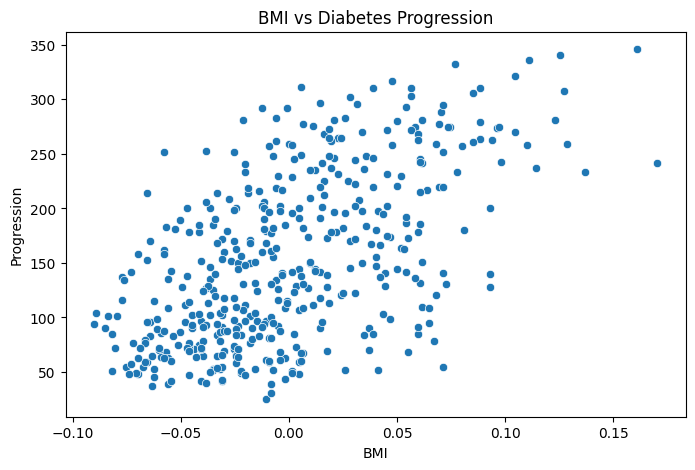

In [6]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='bmi', y='Progression')
plt.title('BMI vs Diabetes Progression')
plt.xlabel('BMI')
plt.ylabel('Progression')
plt.show()


In [7]:

X = df.drop('Progression', axis=1)
y = df['Progression']


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Data normalization completed successfully!")


Training data shape: (353, 10)
Testing data shape: (89, 10)
Data normalization completed successfully!


In [8]:
model = Sequential([
    Dense(64, activation='relu', input_shape=(10,)),
    Dense(32, activation='relu'),
    Dense(1, activation='linear')
])



model.compile(
    optimizer='adam',
    loss='mean_squared_error',
    metrics=['mae']
)



model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,817 (11.00 KB)

 Trainable params: 2,817 (11.00 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

print("Model training completed successfully!")


Epoch 1/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - loss: 31382.1035 - mae: 158.2492 - val_loss: 22257.4551 - val_mae: 133.2801
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 30983.4473 - mae: 157.1019 - val_loss: 21910.5293 - val_mae: 132.0841
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 30385.4531 - mae: 155.3632 - val_loss: 21370.6836 - val_mae: 130.2259
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 29422.0195 - mae: 152.6300 - val_loss: 20558.5527 - val_mae: 127.4057
Epoch 5/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 27946.5293 - mae: 148.3633 - val_loss: 19401.0918 - val_mae: 123.3280
Epoch 6/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 25895.5645 - mae: 142.1982 - val_loss: 17810.9902 - val_mae: 117.5345
Epoch 7/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 23057.5859 - mae: 133.4438 - val_loss: 15795.8555 - val_mae: 109.6846
Epoch 8/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 19752.3652 - mae: 121.9678 - val_loss

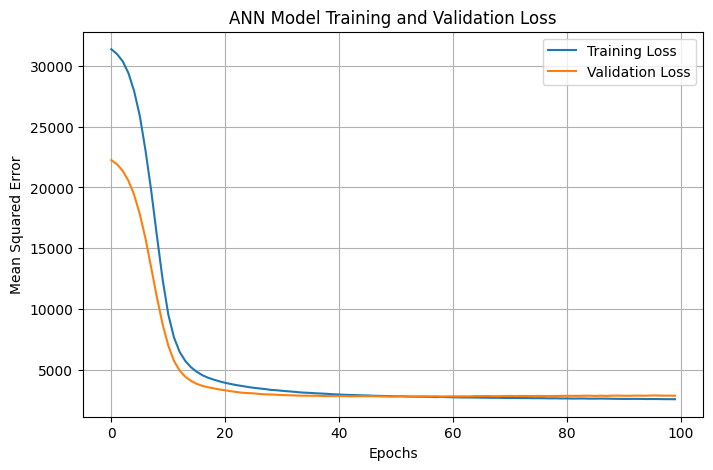

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('ANN Model Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.grid(True)
plt.show()


In [11]:
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Mean Squared Error (MSE):", round(mse, 2))
print("R2 Score:", round(r2, 4))


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Model Evaluation Results
------------------------
Mean Squared Error (MSE): 2824.0
R2 Score: 0.467


In [12]:
improved_model = Sequential([
    tf.keras.layers.Input(shape=(10,)),
    Dense(128, activation='relu'),
    Dropout(0.1),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1, activation='linear')
])

improved_model.compile(
    optimizer='adam',
    loss='mean_squared_error',
    metrics=['mae']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True
)

print("Improved ANN model created successfully!")
improved_model.summary()


Improved ANN model created successfully!


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,777 (46.00 KB)

 Trainable params: 11,777 (46.00 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
improved_history = improved_model.fit(
    X_train,
    y_train,
    epochs=200,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

print("Improved model training completed!")


Epoch 1/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 2710.2620 - mae: 41.5925 - val_loss: 2868.2808 - val_mae: 42.3110
Epoch 2/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 2825.7097 - mae: 42.2668 - val_loss: 2887.5894 - val_mae: 42.6943
Epoch 3/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 2783.0090 - mae: 42.1802 - val_loss: 2890.2439 - val_mae: 42.7172
Epoch 4/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 2763.4851 - mae: 42.1079 - val_loss: 2872.6382 - val_mae: 42.4876
Epoch 5/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 2759.2805 - mae: 41.9081 - val_loss: 2854.2949 - val_mae: 42.2579
Epoch 6/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 2705.7024 - mae: 41.9306 - val_loss: 2872.1536 - val_mae: 42.5907
Epoch 7/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 2689.3826 - mae: 41.1779 - val_loss: 2883.8848 - val_mae: 42.4928
Epoch 8/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 2699.3787 - mae: 41.1939 - val_loss: 2901.1152 - val_mae: 42

In [17]:
improved_pred = improved_model.predict(X_test)

improved_mse = mean_squared_error(y_test, improved_pred)
improved_r2 = r2_score(y_test, improved_pred)

print("Improved Model Results")
print("----------------------")
print("MSE:", round(improved_mse, 2))
print("R2 Score:", round(improved_r2, 4))


print("\nModel Comparison")
print("----------------------")
print("Original ANN MSE:", round(mse, 2))
print("Improved ANN MSE:", round(improved_mse, 2))
print("Original ANN R2:", round(r2, 4))
print("Improved ANN R2:", round(improved_r2, 4))


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
Improved Model Results
----------------------
MSE: 2895.51
R2 Score: 0.4535

Model Comparison
----------------------
Original ANN MSE: 2824.0
Improved ANN MSE: 2895.51
Original ANN R2: 0.467
Improved ANN R2: 0.4535


In [18]:
optimized_model = Sequential([
    tf.keras.layers.Input(shape=(10,)),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1, activation='linear')
])



optimized_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss='mean_squared_error',
    metrics=['mae']
)



optimized_history = optimized_model.fit(
    X_train,
    y_train,
    epochs=200,
    batch_size=16,
    validation_split=0.2,
    callbacks=[EarlyStopping(
        monitor='val_loss',
        patience=25,
        restore_best_weights=True
    )],
    verbose=1
)

print("Optimized model training completed!")


Epoch 1/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 31603.2559 - mae: 158.8149 - val_loss: 22472.8340 - val_mae: 133.9855
Epoch 2/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 31503.6562 - mae: 158.5168 - val_loss: 22404.1719 - val_mae: 133.7372
Epoch 3/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 31408.1270 - mae: 158.2269 - val_loss: 22336.2207 - val_mae: 133.4884
Epoch 4/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 31311.5820 - mae: 157.9315 - val_loss: 22263.0801 - val_mae: 133.2204
Epoch 5/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 31208.8086 - mae: 157.6140 - val_loss: 22178.8887 - val_mae: 132.9118
Epoch 6/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 31089.2344 - mae: 157.2498 - val_loss: 22082.8301 - val_mae: 132.5594
Epoch 7/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 30949.5957 - mae: 156.8237 - val_loss: 21971.6133 - val_mae: 132.1540
Epoch 8/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 30786.6270 - mae: 156.3248 - v

In [19]:
optimized_pred = optimized_model.predict(X_test)

optimized_mse = mean_squared_error(y_test, optimized_pred)
optimized_r2 = r2_score(y_test, optimized_pred)

print("Optimized Model Results")
print("-----------------------")
print("MSE:", round(optimized_mse, 2))
print("R2 Score:", round(optimized_r2, 4))

print("\nFinal Model Comparison")
print("-----------------------")
print("Original ANN:", round(mse, 2), round(r2, 4))
print("Improved ANN:", round(improved_mse, 2), round(improved_r2, 4))
print("Optimized ANN:", round(optimized_mse, 2), round(optimized_r2, 4))


1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
Optimized Model Results
-----------------------
MSE: 2992.67
R2 Score: 0.4351

Final Model Comparison
-----------------------
Original ANN: 2824.0 0.467
Improved ANN: 2895.51 0.4535
Optimized ANN: 2992.67 0.4351


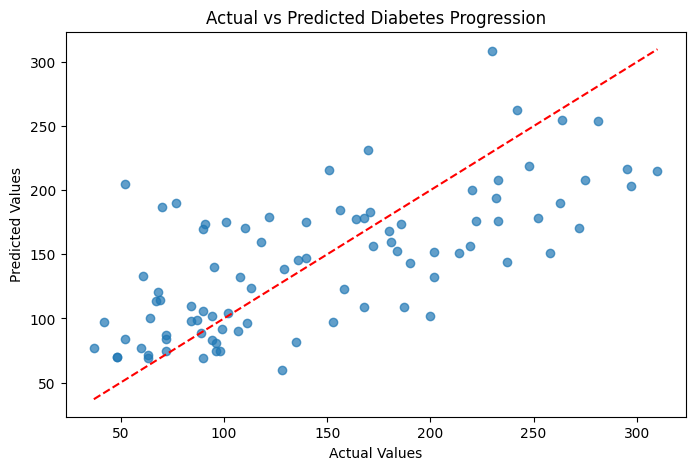

In [20]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.title('Actual vs Predicted Diabetes Progression')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.show()


## Conclusion

In this assignment, an Artificial Neural Network (ANN) was developed to predict diabetes progression using the Diabetes dataset available in the Scikit-learn library.

The dataset contained 442 records and 10 independent features. Data preprocessing, missing value checking, feature normalization, and exploratory data analysis were performed successfully.

An ANN model was developed using two hidden layers with 64 and 32 neurons. The model was trained using the Adam optimizer and Mean Squared Error loss function.

The original ANN achieved an MSE of 2824.00 and an R² score of 0.4670 on the test dataset.

Two additional architectures were tested to improve performance. However, their results were slightly lower than the original model. Therefore, the original ANN was selected as the best-performing model among the three experiments.

This assignment provided practical experience in data preprocessing, visualization, ANN development, model training, evaluation, and hyperparameter experimentation.